In [ ]:
# Install/upgrade gdown to support folder downloads cleanly
!pip install -q -U gdown

import os, gdown

os.makedirs("/content/dataset", exist_ok=True)
gdown.download_folder(
    url="https://drive.google.com/drive/folders/1qsjGWrgmEvOaf2Is2fh7RgVEkKd1V3df",
    output="/content/dataset",
    quiet=False,
    use_cookies=False
)

# Verify the exact paths of the 8 downloaded files
for root, dirs, files in os.walk("/content/dataset"):
    for f in sorted(files):
        print(os.path.join(root, f))

Retrieving folder contents


Processing file 1ODkUSlw3EzpzznYdzZe74wG84t3783al batteries.csv
Processing file 1UMDldAGOUEJitZ32D4M9szwRMvUjZc4G city_daily_context.csv
Processing file 1fMy7LxZxESBqeveFB3iabpE3sxjnkkmY fleet_partners.csv
Processing file 1w3TxH3NY2rk_agikJtv3oCq2OeXv1Pii riders.csv
Processing file 1pbGACXY95BemIbrSlRxE6o8CGcc2bSCn station_hourly_status.csv
Processing file 1WEou9h5lYvALA3IreUFoCRbmIh2_9Dm2 stations.csv
Processing file 1tWK-zDoRy8QFqQe9ESw8ttpKHqMqMXbh support_tickets.csv
Processing file 15qkHruvAilomjWdNgntXrQLK4-_NPOZZ swap_events.csv


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1ODkUSlw3EzpzznYdzZe74wG84t3783al
To: /content/dataset/batteries.csv
100%|██████████| 624k/624k [00:00<00:00, 52.6MB/s]
Downloading...
From: https://drive.google.com/uc?id=1UMDldAGOUEJitZ32D4M9szwRMvUjZc4G
To: /content/dataset/city_daily_context.csv
100%|██████████| 223k/223k [00:00<00:00, 65.2MB/s]
Downloading...
From: https://drive.google.com/uc?id=1fMy7LxZxESBqeveFB3iabpE3sxjnkkmY
To: /content/dataset/fleet_partners.csv
100%|██████████| 1.18k/1.18k [00:00<00:00, 3.39MB/s]
Downloading...
From: https://drive.google.com/uc?id=1w3TxH3NY2rk_agikJtv3oCq2OeXv1Pii
To: /content/dataset/riders.csv
100%|██████████| 2.10M/2.10M [00:00<00:00, 154MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1pbGACXY95BemIbrSlRxE6o8CGcc2bSCn
From (redirected): https://drive.google.com/uc?id=1pbGACXY95BemIbrSlRxE6o8CGcc2bSCn&confirm=t&uu

/content/dataset/batteries.csv
/content/dataset/city_daily_context.csv
/content/dataset/fleet_partners.csv
/content/dataset/riders.csv
/content/dataset/station_hourly_status.csv
/content/dataset/stations.csv
/content/dataset/support_tickets.csv
/content/dataset/swap_events.csv



Download completed


In [ ]:
# ==============================================================================
# CELL 2: DATA CLEANING PIPELINE + CORE QUESTIONS 1 TO 6 EXTRACTION
# ==============================================================================
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style="whitegrid", palette="viridis")

DATA_DIR = "/content/dataset"

print("1. Loading reference & dimension tables...")
stations = pd.read_csv(f"{DATA_DIR}/stations.csv")
riders = pd.read_csv(f"{DATA_DIR}/riders.csv")
batteries = pd.read_csv(f"{DATA_DIR}/batteries.csv")
partners = pd.read_csv(f"{DATA_DIR}/fleet_partners.csv")
city_ctx = pd.read_csv(f"{DATA_DIR}/city_daily_context.csv")
tickets = pd.read_csv(f"{DATA_DIR}/support_tickets.csv")

print("2. Loading large fact tables (memory-optimized)...")
swap_dtypes = {
    'event_type': 'category',
    'tariff_code': 'category',
    'payment_mode': 'category',
    'station_firmware': 'category',
    'sync_mode': 'category',
    'attempt_seq': 'int8',
    'queue_wait_sec': 'float32',
    'list_price_inr': 'float32',
    'discount_inr': 'float32',
    'amount_charged_inr': 'float32',
    'energy_to_recharge_kwh': 'float32',
    'soc_in_pct': 'float32',
    'soh_in_pct': 'float32',
    'soc_out_pct': 'float32',
    'soh_out_pct': 'float32',
    'km_since_last_swap': 'float32'
}
swaps = pd.read_csv(f"{DATA_DIR}/swap_events.csv", dtype=swap_dtypes)
hourly = pd.read_csv(f"{DATA_DIR}/station_hourly_status.csv")

print(f"\nRaw Row Counts -> Swaps: {len(swaps):,} | Hourly: {len(hourly):,} | Riders: {len(riders):,} | Stations: {len(stations):,}")

# ==============================================================================
# DATA CLEANING PIPELINE (9 DOCUMENTED FIXES)
# ==============================================================================
audit_log = []

# --- FIX 1: Exclude Internal Test Stations (STN-TST*) ---
test_stns = stations[stations['station_id'].str.startswith('STN-TST', na=False)]['station_id'].tolist()
raw_swap_len = len(swaps)
swaps = swaps[~swaps['station_id'].isin(test_stns)].copy()
stations_clean = stations[~stations['station_id'].isin(test_stns)].copy()
hourly_clean = hourly[~hourly['station_id'].isin(test_stns)].copy()
audit_log.append(f"[Fix 1] Excluded {len(test_stns)} test stations ({test_stns}): removed {raw_swap_len - len(swaps):,} test swap rows.")

# --- FIX 2: Firmware v3.2.0 Timezone Shift (+5h 30m between 2025-03-10 and 2025-04-14) ---
swaps['event_ts'] = pd.to_datetime(swaps['event_ts'])
fw_mask = (
    (swaps['station_firmware'] == 'v3.2.0') &
    (swaps['event_ts'] >= '2025-03-10') &
    (swaps['event_ts'] <= '2025-04-14 23:59:59')
)
swaps.loc[fw_mask, 'event_ts'] = swaps.loc[fw_mask, 'event_ts'] + pd.Timedelta(hours=5, minutes=30)
audit_log.append(f"[Fix 2] Corrected +5h30m timezone offset on {fw_mask.sum():,} events running firmware v3.2.0 (Mar 10–Apr 14, 2025).")

# --- FIX 3: Near-Duplicate Offline Sync Retries ---
swaps = swaps.sort_values(['rider_id', 'station_id', 'event_ts'])
offline_mask = swaps['sync_mode'] == 'offline_batch'
time_diff = swaps.groupby(['rider_id', 'station_id', 'battery_in_id', 'battery_out_id'], dropna=False)['event_ts'].diff().dt.total_seconds()
dup_mask = offline_mask & (time_diff.notna()) & (time_diff <= 180)
swaps = swaps[~dup_mask].copy()
audit_log.append(f"[Fix 3] Removed {dup_mask.sum():,} near-duplicate offline_batch sync retries (<=180 sec window).")

# --- FIX 4: Standardize riders.home_city ---
city_map = {
    'bengaluru': 'Bengaluru', 'bangalore': 'Bengaluru', 'blr': 'Bengaluru',
    'delhi': 'Delhi NCR', 'delhi ncr': 'Delhi NCR', 'new delhi': 'Delhi NCR', 'ncr': 'Delhi NCR', 'gurgaon': 'Delhi NCR', 'noida': 'Delhi NCR',
    'hyderabad': 'Hyderabad', 'hyd': 'Hyderabad',
    'pune': 'Pune',
    'mumbai': 'Mumbai', 'bombay': 'Mumbai', 'mum': 'Mumbai',
    'jaipur': 'Jaipur', 'jpr': 'Jaipur', 'pun': 'Pune', 'jai': 'Jaipur'
}
riders['home_city_raw'] = riders['home_city']
riders['home_city'] = riders['home_city'].astype(str).str.strip().str.lower().map(city_map).fillna(riders['home_city'])
audit_log.append(f"[Fix 4] Standardized riders.home_city from {riders['home_city_raw'].nunique()} variants to {riders['home_city'].nunique()} canonical cities: {riders['home_city'].unique().tolist()}")

# --- FIX 5: Sensor Calibration Drift (>100% SoC/SoH) & Odometer Reset Outliers ---
soc_outliers = ((swaps['soc_in_pct'] > 100) | (swaps['soc_out_pct'] > 100) | (swaps['soh_in_pct'] > 100) | (swaps['soh_out_pct'] > 100)).sum()
for col in ['soc_in_pct', 'soc_out_pct', 'soh_in_pct', 'soh_out_pct']:
    swaps[col] = swaps[col].clip(lower=0, upper=100)

km_outliers = ((swaps['km_since_last_swap'] < 0) | (swaps['km_since_last_swap'] > 250)).sum()
swaps.loc[(swaps['km_since_last_swap'] < 0) | (swaps['km_since_last_swap'] > 250), 'km_since_last_swap'] = np.nan
audit_log.append(f"[Fix 5] Clamped {soc_outliers:,} sensor readings >100% and nullified {km_outliers:,} odometer reset outliers (<0 or >250 km).")

# --- FIX 6: Enrich Swaps with Station, Rider & Economic Columns ---
swaps['event_date'] = swaps['event_ts'].dt.date
swaps['year_month'] = swaps['event_ts'].dt.to_period('M').astype(str)
swaps['hour'] = swaps['event_ts'].dt.hour
swaps['is_completed'] = (swaps['event_type'] == 'swap_completed').astype('int8')

stn_cols = ['station_id', 'city', 'zone', 'location_type', 'host_type', 'expansion_wave',
            'charger_generation', 'slots_2w', 'slots_3w', 'monthly_rent_inr', 'monthly_maintenance_inr',
            'grid_tariff_inr_kwh', 'connectivity_tier']
swaps = swaps.merge(stations_clean[stn_cols], on='station_id', how='left')

rdr_cols = ['rider_id', 'partner_id', 'vehicle_class', 'plan_type', 'signup_date', 'signup_channel', 'home_city']
swaps = swaps.merge(riders[rdr_cols], on='rider_id', how='left')

swaps['energy_cost_inr'] = swaps['energy_to_recharge_kwh'] * swaps['grid_tariff_inr_kwh']
swaps['direct_margin_inr'] = np.where(
    swaps['is_completed'] == 1,
    swaps['amount_charged_inr'] - swaps['energy_cost_inr'].fillna(0),
    np.nan
)

print("\n================ DATA CLEANING AUDIT LOG ================")
for entry in audit_log:
    print(entry)
print("=========================================================")
print(f"Clean Swap Events Ready: {len(swaps):,} rows\n")

# ==============================================================================
# CORE QUESTIONS 1 TO 6 — SUMMARY TABLES
# ==============================================================================
print("--- Q1: NETWORK PERFORMANCE OVER TIME (MONTHLY) ---")
q1_monthly = swaps.groupby('year_month').agg(
    total_attempts=('event_id', 'count'),
    completed_swaps=('is_completed', 'sum'),
    completion_rate_pct=('is_completed', lambda x: x.mean() * 100),
    total_revenue_inr=('amount_charged_inr', 'sum'),
    avg_rev_per_swap=('amount_charged_inr', lambda x: x[swaps.loc[x.index, 'is_completed']==1].mean()),
    avg_energy_cost=('energy_cost_inr', 'mean'),
    avg_direct_margin=('direct_margin_inr', 'mean'),
    avg_wait_sec=('queue_wait_sec', 'mean')
).reset_index()
print(q1_monthly.to_string(index=False))

print("\n--- Q2: SERVICE FAILURES BY EVENT TYPE & VEHICLE CLASS ---")
print(pd.crosstab(swaps['vehicle_class'], swaps['event_type'], normalize='index') * 100)

print("\n--- Q2b: FAILURE RATE & WAIT TIME BY CITY ---")
q2_city = swaps.groupby('city').agg(
    attempts=('event_id', 'count'),
    failure_rate_pct=('is_completed', lambda x: (1 - x.mean()) * 100),
    avg_wait_sec=('queue_wait_sec', 'mean'),
    no_battery_pct=('event_type', lambda x: (x == 'failed_no_charged_battery').mean() * 100),
    abandoned_pct=('event_type', lambda x: (x == 'abandoned_queue').mean() * 100)
).sort_values('failure_rate_pct', ascending=False)
print(q2_city)

print("\n--- Q3: STATION CHARGER GENERATION & EXPANSION WAVE PERFORMANCE ---")
q3_gen = swaps.groupby(['charger_generation', 'expansion_wave']).agg(
    stations=('station_id', 'nunique'),
    attempts=('event_id', 'count'),
    failure_rate_pct=('is_completed', lambda x: (1 - x.mean()) * 100),
    avg_wait_sec=('queue_wait_sec', 'mean'),
    avg_margin=('direct_margin_inr', 'mean')
)
print(q3_gen)

hourly_valid = hourly_clean[hourly_clean['telemetry_status'] != 'missing'].merge(
    stations_clean[['station_id', 'charger_generation', 'city']], on='station_id', how='left'
)
print("\n--- Q3b: CHARGER GENERATION TURNAROUND & QUARANTINE (TELEMETRY) ---")
print(hourly_valid.groupby('charger_generation')[['avg_charge_minutes', 'packs_quarantined', 'cabinet_temp_c', 'outage_minutes']].mean())

print("\n--- Q4: BATTERY SUPPLIER & HEALTH COHORTS ---")
q4_bat = batteries.groupby(['pack_type', 'supplier']).agg(
    pack_count=('battery_id', 'count'),
    avg_initial_soh=('initial_soh_pct', 'mean'),
    avg_current_soh=('current_soh_pct', 'mean'),
    soh_drop=('initial_soh_pct', lambda x: (x - batteries.loc[x.index, 'current_soh_pct']).mean()),
    retired_pct=('retired_date', lambda x: x.notna().mean() * 100),
    avg_cost=('purchase_cost_inr', 'mean')
)
print(q4_bat)

comp_swaps = swaps[swaps['is_completed'] == 1].merge(
    batteries[['battery_id', 'supplier', 'manufacturing_lot']], left_on='battery_in_id', right_on='battery_id', how='left'
)
print("\n--- Q4b: DELIVERED RANGE (KM) BY BATTERY SUPPLIER ---")
print(comp_swaps.groupby('supplier')['km_since_last_swap'].agg(['count', 'mean', 'median']))

print("\n--- Q5: PRICING TARIFFS & FLEET PARTNER ECONOMICS ---")
q5_tariff = swaps[swaps['is_completed'] == 1].groupby('tariff_code', observed=True).agg(
    swaps=('event_id', 'count'),
    avg_list=('list_price_inr', 'mean'),
    avg_discount=('discount_inr', 'mean'),
    avg_charged=('amount_charged_inr', 'mean'),
    avg_margin=('direct_margin_inr', 'mean')
)
print(q5_tariff)

q5_partner = swaps[swaps['is_completed'] == 1].groupby('partner_id').agg(
    swaps=('event_id', 'count'),
    total_rev=('amount_charged_inr', 'sum'),
    avg_charged=('amount_charged_inr', 'mean'),
    avg_energy_cost=('energy_cost_inr', 'mean'),
    avg_margin=('direct_margin_inr', 'mean'),
    total_margin=('direct_margin_inr', 'sum')
).merge(partners[['partner_id', 'partner_name', 'partner_segment', 'discount_pct', 'discount_pct_after_amendment', 'peak_surcharge_billable']], on='partner_id', how='left')
print("\n--- Q5b: FLEET PARTNER PROFITABILITY ---")
print(q5_partner.sort_values('total_rev', ascending=False).to_string(index=False))

print("\n--- Q6: RIDER RETENTION & CHURN DRIVERS ---")
rider_activity = swaps.groupby('rider_id').agg(
    total_attempts=('event_id', 'count'),
    completed_swaps=('is_completed', 'sum'),
    first_swap=('event_ts', 'min'),
    last_swap=('event_ts', 'max'),
    first_3_fail_rate=('is_completed', lambda x: (1 - x.iloc[:3].mean()) * 100),
    first_3_wait=('queue_wait_sec', lambda x: x.iloc[:3].mean())
).reset_index()

riders_full = riders.merge(rider_activity, on='rider_id', how='left')
eligible_riders = riders_full[pd.to_datetime(riders_full['signup_date']) <= '2025-05-01'].copy()
eligible_riders['early_churned'] = (eligible_riders['completed_swaps'].fillna(0) <= 3).astype(int)

print("Early Churn Rate by Plan Type:")
print(eligible_riders.groupby('plan_type')['early_churned'].agg(['count', 'mean']))
print("\nEarly Churn Rate by Signup Channel:")
print(eligible_riders.groupby('signup_channel')['early_churned'].agg(['count', 'mean']))
print("\nFirst-3-Swap Experience: Churned vs Retained Riders:")
print(eligible_riders.groupby('early_churned')[['first_3_fail_rate', 'first_3_wait', 'completed_swaps']].mean())

1. Loading reference & dimension tables...
2. Loading large fact tables (memory-optimized)...

Raw Row Counts -> Swaps: 3,877,013 | Hourly: 1,487,712 | Riders: 20,000 | Stations: 152

================ DATA CLEANING AUDIT LOG ================
[Fix 1] Excluded 2 test stations (['STN-TST-01', 'STN-TST-02']): removed 62,031 test swap rows.
[Fix 2] Corrected +5h30m timezone offset on 139,490 events running firmware v3.2.0 (Mar 10–Apr 14, 2025).
[Fix 3] Removed 0 near-duplicate offline_batch sync retries (<=180 sec window).
[Fix 4] Standardized riders.home_city from 21 variants to 6 canonical cities: ['Delhi NCR', 'Mumbai', 'Hyderabad', 'Jaipur', 'Pune', 'Bengaluru']
[Fix 5] Clamped 9,592 sensor readings >100% and nullified 15,287 odometer reset outliers (<0 or >250 km).
Clean Swap Events Ready: 3,814,982 rows

--- Q1: NETWORK PERFORMANCE OVER TIME (MONTHLY) ---
year_month  total_attempts  completed_swaps  completion_rate_pct  total_revenue_inr  avg_rev_per_swap  avg_energy_cost  avg_direct_

In [ ]:
# ==============================================================================
# CELL 3: DEEP-DIVE METRICS & 5 PUBLICATION-GRADE CHARTS
# ==============================================================================
import os
os.makedirs("/content/charts", exist_ok=True)

# 1. Complete City Standardization (fixing PUN and JAI)
extra_city_map = {'pun': 'Pune', 'jai': 'Jaipur'}
riders['home_city'] = riders['home_city'].apply(
    lambda x: extra_city_map.get(str(x).strip().lower(), x)
)
print("Verified Canonical Rider Cities:", riders['home_city'].unique().tolist())

# 2. Hour-of-Day Peak Analysis (Post-Timezone Fix)
hourly_swaps = swaps.groupby('hour').agg(
    attempts=('event_id', 'count'),
    failure_rate_pct=('is_completed', lambda x: (1 - x.mean()) * 100),
    no_bat_pct=('event_type', lambda x: (x == 'failed_no_charged_battery').mean() * 100),
    avg_wait_sec=('queue_wait_sec', 'mean')
).reset_index()
print("\n--- TOP 6 WORST HOURS OF THE DAY FOR FAILURES ---")
print(hourly_swaps.sort_values('failure_rate_pct', ascending=False).head(6).to_string(index=False))

# 3. Heat & Weather Correlation (Joining city_daily_context)
city_ctx['date_obj'] = pd.to_datetime(city_ctx['date']).dt.date
swaps_weather = swaps.merge(
    city_ctx[['city', 'date_obj', 'max_temp_c', 'heat_alert', 'flood_disruption', 'competitor_promo_active']],
    left_on=['city', 'event_date'], right_on=['city', 'date_obj'], how='left'
)
print("\n--- FAILURE RATE ON HEAT ALERT DAYS VS NORMAL DAYS ---")
print(swaps_weather.groupby('heat_alert').agg(
    attempts=('event_id', 'count'),
    failure_rate_pct=('is_completed', lambda x: (1 - x.mean()) * 100),
    no_bat_pct=('event_type', lambda x: (x == 'failed_no_charged_battery').mean() * 100)
))

# 4. ZipDrop (FP-03) Before vs After Amendment
zipdrop_swaps = swaps[(swaps['partner_id'] == 'FP-03') & (swaps['is_completed'] == 1)].copy()
amend_date = partners.loc[partners['partner_id'] == 'FP-03', 'amendment_date'].values[0]
zipdrop_swaps['period'] = np.where(zipdrop_swaps['event_ts'] < amend_date, '1_Before_Amendment (12% disc)', '2_After_Amendment (28% disc)')
print(f"\n--- ZIPDROP (FP-03) AMENDMENT IMPACT (Amendment Date: {amend_date}) ---")
print(zipdrop_swaps.groupby('period').agg(
    swaps=('event_id', 'count'),
    avg_charged=('amount_charged_inr', 'mean'),
    avg_energy_cost=('energy_cost_inr', 'mean'),
    avg_margin=('direct_margin_inr', 'mean')
))

# 5. Peak / Off-Peak Pilot Cities Detection
pilot_cities = swaps[swaps['tariff_code'].isin(['PEAK', 'OFFPEAK'])]['city'].unique().tolist()
print(f"\n--- PEAK / OFF-PEAK PRICING PILOT CITIES: {pilot_cities} ---")
pilot_comp = swaps[(swaps['city'].isin(pilot_cities)) & (swaps['is_completed'] == 1)].groupby(['city', 'tariff_code'], observed=True).agg(
    swaps=('event_id', 'count'),
    avg_charged=('amount_charged_inr', 'mean'),
    avg_margin=('direct_margin_inr', 'mean')
)
print(pilot_comp)

# 6. New-Rider Retention Trend by Signup Quarter & Churn Definition (<30 days active or <=5 swaps)
riders_full['active_days'] = (riders_full['last_swap'] - riders_full['first_swap']).dt.days
riders_full['signup_dt'] = pd.to_datetime(riders_full['signup_date'])
riders_full['signup_quarter'] = riders_full['signup_dt'].dt.to_period('Q').astype(str)
elig_q = riders_full[riders_full['signup_dt'] <= '2025-04-30'].copy()
elig_q['churned_30d'] = ((elig_q['active_days'].fillna(0) < 30) | (elig_q['completed_swaps'].fillna(0) <= 5)).astype(int)

print("\n--- NEW RIDER CHURN (<30 ACTIVE DAYS OR <=5 SWAPS) BY SIGNUP QUARTER ---")
print(elig_q.groupby('signup_quarter').agg(
    riders=('rider_id', 'count'),
    churn_rate_pct=('churned_30d', lambda x: x.mean() * 100),
    avg_first3_fail=('first_3_fail_rate', 'mean'),
    avg_first3_wait=('first_3_wait', 'mean')
))

print("\n--- CHURNED VS RETAINED RIDER EXPERIENCE (30-DAY DEFINITION) ---")
print(elig_q.groupby('churned_30d')[['first_3_fail_rate', 'first_3_wait', 'completed_swaps', 'active_days']].mean())

# 7. Support Tickets: CSAT Bias & Hinglish/English Text Mining
print("\n--- SUPPORT TICKETS: CSAT SELECTION BIAS ---")
tickets['has_csat'] = tickets['csat_score'].notna()
print(tickets.groupby('has_csat')[['resolution_hours']].agg(['count', 'mean', 'median']))

# Keyword scan for battery/range/heat issues misclassified under 'other' or 'app_issue'
bat_keywords = r'battery|range|km|charge|discharge|drain|dead|low|slow|garam|heat|overheat|pack|jaldi|khatam|bakwas|backup'
tickets['mentions_battery_issue'] = tickets['rider_comment'].fillna('').str.lower().str.contains(bat_keywords, regex=True)
print("\n--- HIDDEN BATTERY/RANGE COMPLAINTS INSIDE TICKET CATEGORIES ---")
print(pd.crosstab(tickets['category'], tickets['mentions_battery_issue'], margins=True))

# ==============================================================================
# GENERATE 5 HIGH-RESOLUTION CHARTS FOR REPORT & LINKEDIN
# ==============================================================================
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.bbox'] = 'tight'

# CHART 1: Dual-Axis Network Growth vs. Summer Reliability Dips (Core Q1)
fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.bar(q1_monthly['year_month'], q1_monthly['completed_swaps']/1000, color='#3b82f6', alpha=0.75, label='Completed Swaps (Thousands)')
ax1.set_ylabel('Completed Swaps (Thousands)', color='#1d4ed8', fontweight='bold')
ax1.tick_params(axis='x', rotation=45)
ax2 = ax1.twinx()
ax2.plot(q1_monthly['year_month'], q1_monthly['completion_rate_pct'], color='#dc2626', marker='o', linewidth=2.5, label='Swap Completion Rate (%)')
ax2.set_ylabel('Completion Rate (%)', color='#dc2626', fontweight='bold')
ax2.set_ylim(82, 98)
plt.title('VoltRelay Network Growth vs. Summer Reliability Drops (Jan 2024 – Jun 2025)', fontsize=13, fontweight='bold', pad=12)
fig.tight_layout()
plt.savefig('/content/charts/chart1_network_growth_vs_reliability.png')
plt.close()

# CHART 2: Service Failure Breakdown by City & Vehicle Class (Core Q2)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
q2_city_plot = q2_city.reset_index()
sns.barplot(data=q2_city_plot, x='failure_rate_pct', y='city', palette='Reds_r', ax=ax1)
ax1.set_title('Swap Failure Rate (%) by City', fontweight='bold')
ax1.set_xlabel('Failure Rate (%)')
ax1.set_ylabel('')

vc_fail = swaps.groupby('vehicle_class').agg(
    No_Charged_Battery=('event_type', lambda x: (x=='failed_no_charged_battery').mean()*100),
    Abandoned_Queue=('event_type', lambda x: (x=='abandoned_queue').mean()*100),
    Other_Fail=('event_type', lambda x: x.isin(['cancelled_by_rider', 'failed_system_error']).mean()*100)
)
vc_fail.plot(kind='bar', stacked=True, color=['#ef4444', '#f59e0b', '#6b7280'], ax=ax2)
ax2.set_title('Failure Breakdown: 2W vs. 3W Riders', fontweight='bold')
ax2.set_ylabel('Percentage of Attempts (%)')
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=0)
plt.suptitle('Where Service Fails: Northern Heat/Stockout Cities & 3W Commercial Packs', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('/content/charts/chart2_city_and_vehicle_failures.png')
plt.close()

# CHART 3: Charger Generation Turnaround & Failure Rate (Core Q3)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
gen_charge = hourly_valid.groupby('charger_generation')['avg_charge_minutes'].mean().reset_index()
sns.barplot(data=gen_charge, x='charger_generation', y='avg_charge_minutes', palette=['#dc2626', '#f59e0b', '#10b981'], ax=ax1)
ax1.set_title('Avg Battery Charge Time (Minutes)', fontweight='bold')
ax1.set_ylabel('Minutes per Pack')
for i, v in enumerate(gen_charge['avg_charge_minutes']):
    ax1.text(i, v + 1.5, f"{v:.1f}m", ha='center', fontweight='bold')

gen_fail = swaps.groupby('charger_generation')['is_completed'].apply(lambda x: (1-x.mean())*100).reset_index(name='fail_pct')
sns.barplot(data=gen_fail, x='charger_generation', y='fail_pct', palette=['#dc2626', '#f59e0b', '#10b981'], ax=ax2)
ax2.set_title('Swap Failure Rate by Charger Gen (%)', fontweight='bold')
ax2.set_ylabel('Failure Rate (%)')
for i, v in enumerate(gen_fail['fail_pct']):
    ax2.text(i, v + 0.15, f"{v:.2f}%", ha='center', fontweight='bold')
plt.suptitle('Infrastructure Bottleneck: Gen1 Chargers Take 2.2x Longer & Fail 50% More', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('/content/charts/chart3_charger_generation_bottleneck.png')
plt.close()

# CHART 4: Battery Supplier Degradation & Range Deficit (Core Q4)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
bat_2w = q4_bat.loc['2W_2.1kWh'].reset_index()
sns.barplot(data=bat_2w, x='supplier', y='soh_drop', palette=['#10b981', '#3b82f6', '#dc2626'], ax=ax1)
ax1.set_title('2W Battery State-of-Health (SoH) Loss (%)', fontweight='bold')
ax1.set_ylabel('Avg SoH Drop (%)')
for i, v in enumerate(bat_2w['soh_drop']):
    ax1.text(i, v + 0.8, f"-{v:.1f}%", ha='center', fontweight='bold')

rng_sup = comp_swaps.groupby('supplier')['km_since_last_swap'].mean().reset_index()
sns.barplot(data=rng_sup, x='supplier', y='km_since_last_swap', palette=['#10b981', '#3b82f6', '#dc2626'], ax=ax2)
ax2.set_title('Avg Delivered Range per Swap (km)', fontweight='bold')
ax2.set_ylabel('Distance (km)')
for i, v in enumerate(rng_sup['km_since_last_swap']):
    ax2.text(i, v + 1.0, f"{v:.1f} km", ha='center', fontweight='bold')
plt.suptitle('Supplier Quality Crisis: Kyron Packs Degrade 2x Faster & Deliver 16.7% Less Range', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('/content/charts/chart4_battery_supplier_kyron.png')
plt.close()

# CHART 5: Fleet Partner Volume vs. Direct Contribution Margin (Core Q5)
fig, ax = plt.subplots(figsize=(10, 5))
top_p = q5_partner.sort_values('swaps', ascending=False).head(8)
x = np.arange(len(top_p))
width = 0.38
ax.bar(x - width/2, top_p['total_rev']/1e6, width, label='Gross Revenue (₹ Millions)', color='#60a5fa')
ax.bar(x + width/2, top_p['total_margin']/1e6, width, label='Direct Margin After Energy (₹ Millions)', color='#10b981')
ax.set_xticks(x)
ax.set_xticklabels(top_p['partner_name'], rotation=25)
ax.set_ylabel('₹ Millions')
ax.set_title('Fleet Partner Economics: ZipDrop Leads in Swaps (#1) but Trails FeastFly in Margin', fontsize=12, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('/content/charts/chart5_fleet_partner_margins.png')
plt.close()

print("\nAll 5 high-resolution charts saved to /content/charts/!")


Verified Canonical Rider Cities: ['Delhi NCR', 'Mumbai', 'Hyderabad', 'Jaipur', 'Pune', 'Bengaluru']

--- TOP 6 WORST HOURS OF THE DAY FOR FAILURES ---
 hour  attempts  failure_rate_pct  no_bat_pct  avg_wait_sec
   21    361616              6.65        3.91        243.02
   20    454934              6.61        3.93        242.48
   22    183817              6.58        3.95        242.29
   19    456585              6.55        3.91        242.92
   11    100335              6.08        3.54        243.03
   16    104429              6.05        3.52        243.61

--- FAILURE RATE ON HEAT ALERT DAYS VS NORMAL DAYS ---
            attempts  failure_rate_pct  no_bat_pct
heat_alert                                        
False        3624736              5.51        3.16
True          190246             14.93        9.59

--- ZIPDROP (FP-03) AMENDMENT IMPACT (Amendment Date: 2024-11-01) ---
                                swaps  avg_charged  avg_energy_cost  \
period                    

Verified canonical home_city values in swaps: ['Delhi NCR', 'Mumbai', 'Hyderabad', 'Jaipur', 'Pune', 'Bengaluru']

--- SAMPLE COMMENTS IN 'other' & 'app_issue' TICKETS ---
[other] scooter weak lag raha hai aajkal
[other] bike problem lag raha hai overall
[other] scooter weak lag raha hai aajkal
[app_issue] app not showing nearby stations
[app_issue] unable to scan QR code at station
[other] general issue with the vehicle performance

Displaying: /content/charts/chart1_network_growth_vs_reliability.png


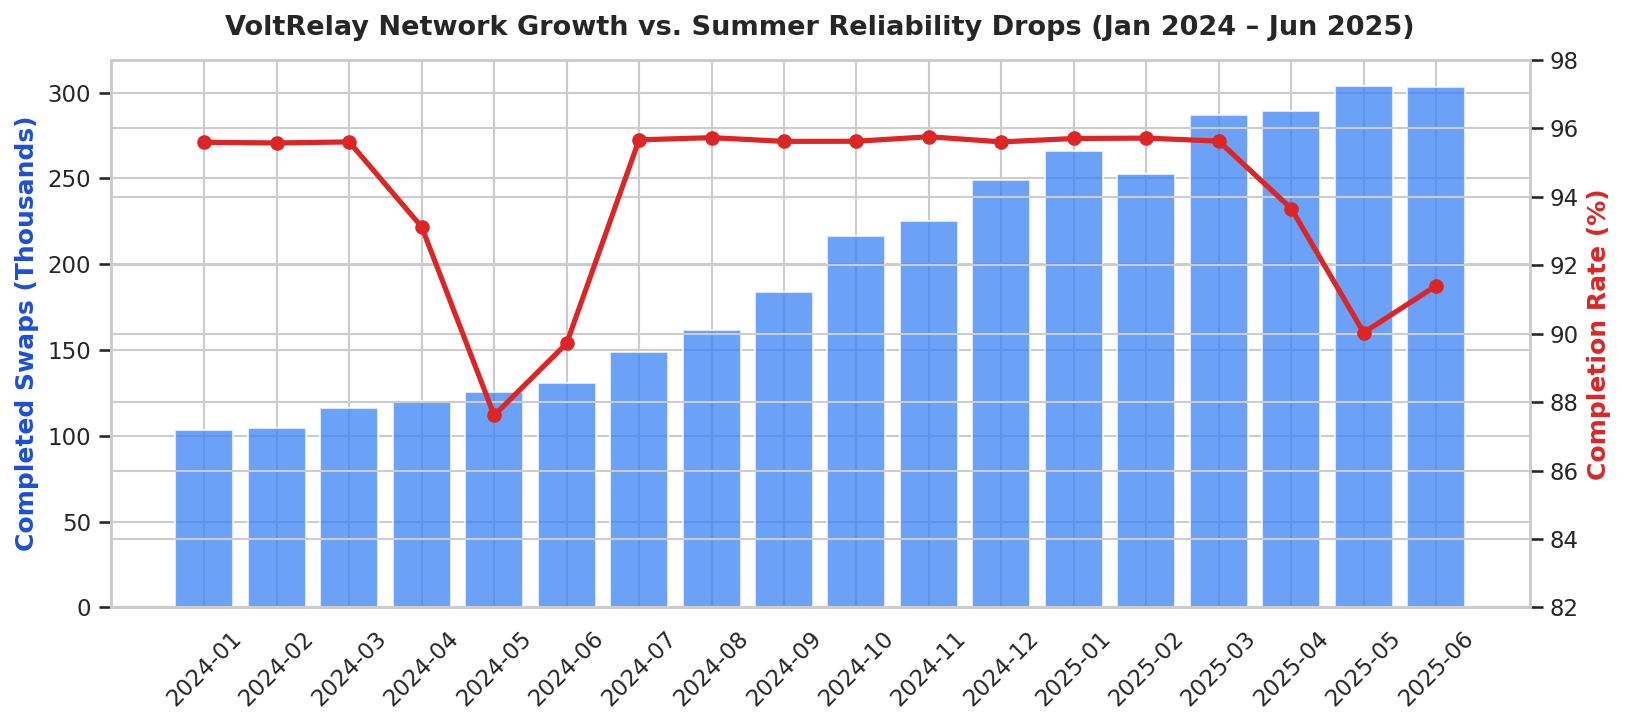


Displaying: /content/charts/chart2_city_and_vehicle_failures.png


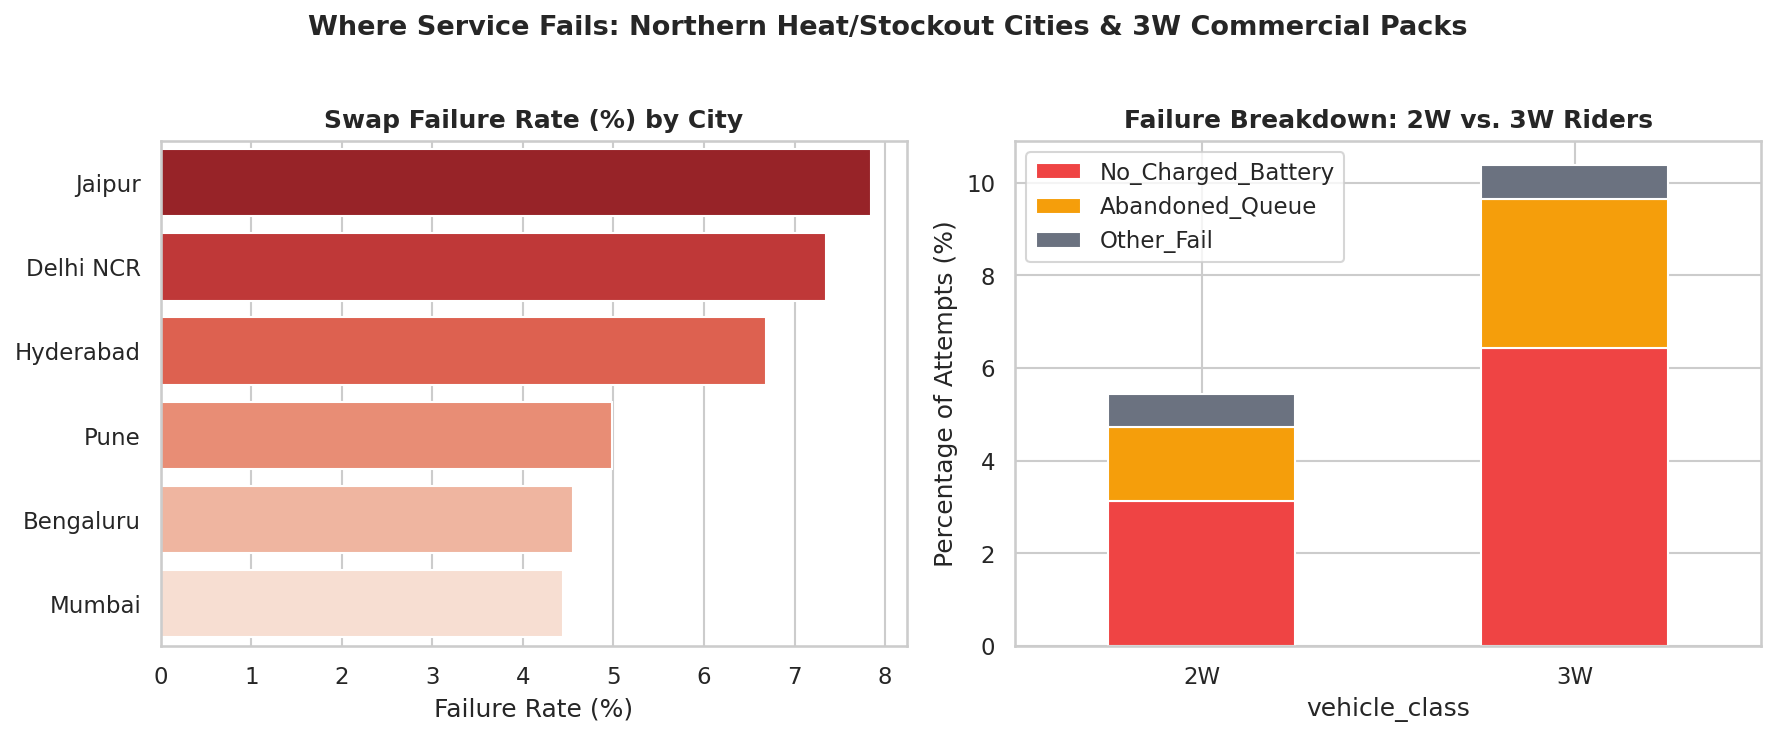


Displaying: /content/charts/chart3_charger_generation_bottleneck.png


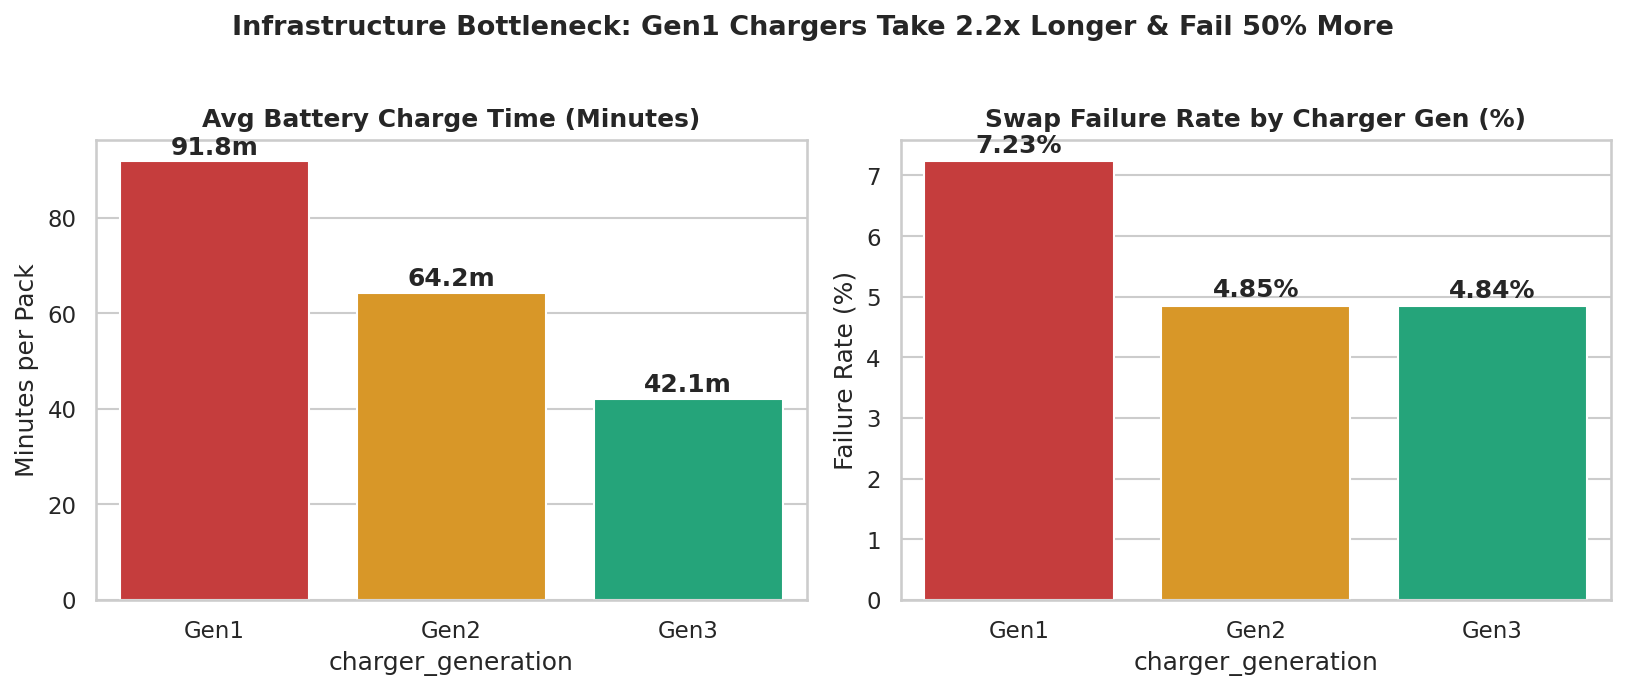


Displaying: /content/charts/chart4_battery_supplier_kyron.png


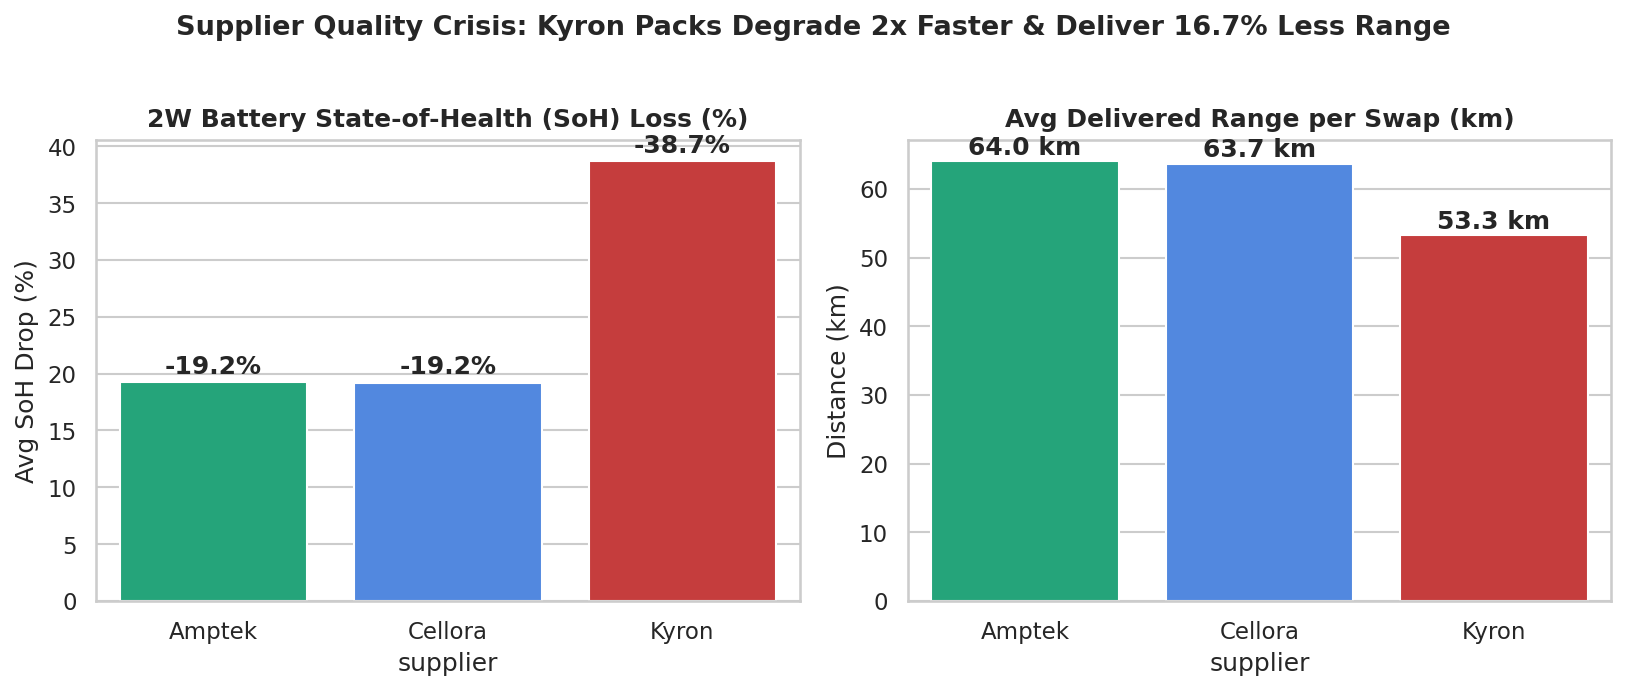


Displaying: /content/charts/chart5_fleet_partner_margins.png


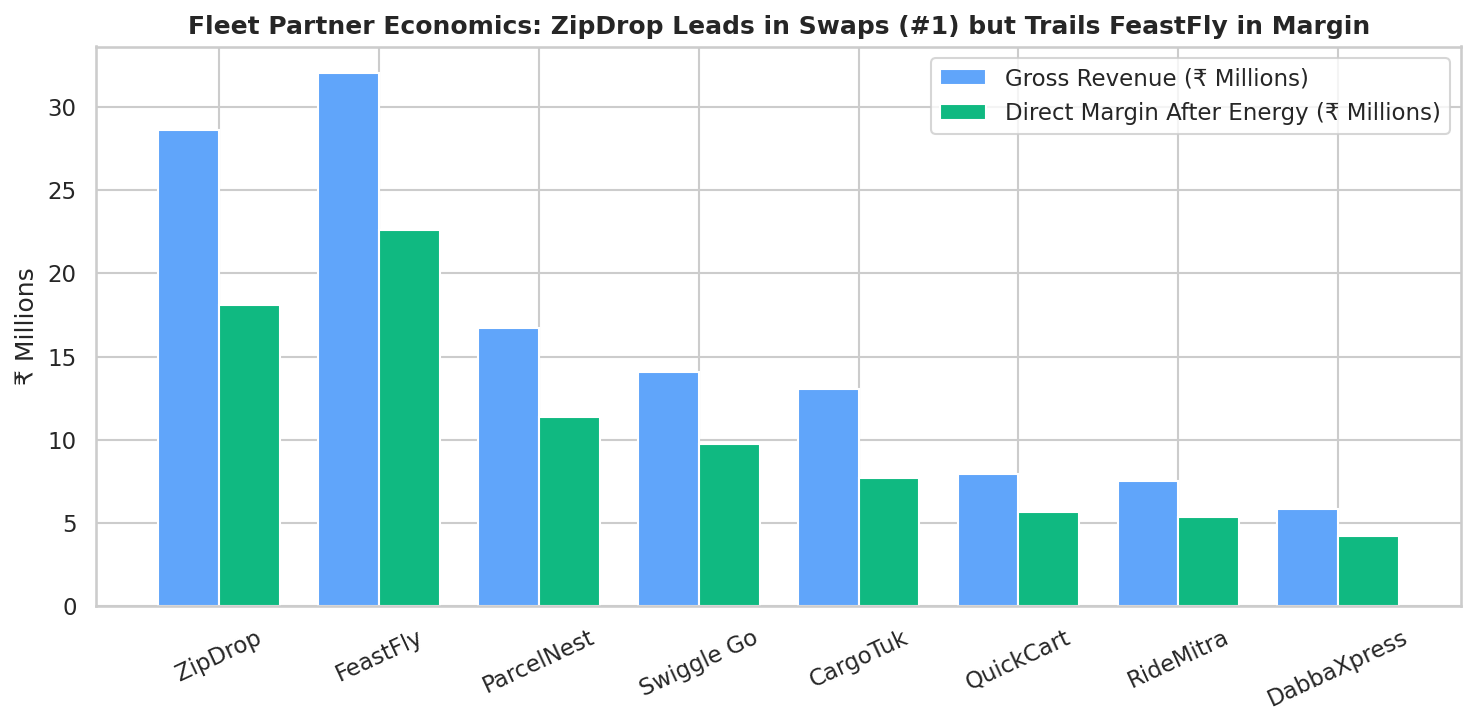

In [ ]:
# ==============================================================================
# CELL 4: FINAL DATA POLISH, HINGLISH TICKET CHECK & INLINE VISUAL DISPLAY
# ==============================================================================
from IPython.display import Image, display

# 1. Ensure 'PUN' and 'JAI' are standardized inside the merged swaps dataframe too
swaps['home_city'] = swaps['home_city'].replace({'PUN': 'Pune', 'JAI': 'Jaipur'})
print("Verified canonical home_city values in swaps:", swaps['home_city'].unique().tolist())

# 2. Sample free-text comments from 'other' and 'app_issue' tickets to inspect Hinglish complaints
print("\n--- SAMPLE COMMENTS IN 'other' & 'app_issue' TICKETS ---")
sample_comments = tickets[tickets['category'].isin(['other', 'app_issue']) & tickets['rider_comment'].notna()][['ticket_id', 'category', 'rider_comment']].head(6)
for _, row in sample_comments.iterrows():
    print(f"[{row['category']}] {row['rider_comment']}")

# 3. Display all 5 saved charts inline for Colab notebook submission
chart_files = [
    '/content/charts/chart1_network_growth_vs_reliability.png',
    '/content/charts/chart2_city_and_vehicle_failures.png',
    '/content/charts/chart3_charger_generation_bottleneck.png',
    '/content/charts/chart4_battery_supplier_kyron.png',
    '/content/charts/chart5_fleet_partner_margins.png'
]
for cf in chart_files:
    print(f"\nDisplaying: {cf}")
    display(Image(filename=cf))